This example shows how to treat `stages` as a modular part of a whole assessment

In [75]:
from analysisManager import basicSampler, searchRoutine

sampler = basicSampler(
	depth = (0.3,0.5),
	width = (0.1,0.3)
)
searcher = searchRoutine(sampler = sampler,method='grid',density = 5)

In this example, we will create some initial stages which are a low fidelity representation just to start

In [76]:
from analysisManager import stage

load = 1e3 # 1kN load
length = 2 # 2m long cantilever
youngsModulus = 200e8 # for steel
density = 7850 # for steel

def rectangularCantileverDeflection(depth,width,**kwargs):
	I = depth**3 * width / 12
	deflection = load * length**3 / (4 * youngsModulus * I)
	return {'deflection':deflection}
deflectionStage = stage(rectangularCantileverDeflection, inputs = ['depth','width'],name = 'Cantilever deflection')

def getMass(depth,width,**kwargs):
	volume = depth * width * length
	mass = volume * density
	return {'mass':mass}

massStage = stage(getMass,inputs = ['depth','width'],name = 'Mass')

stages = [deflectionStage,massStage]

In [77]:
from analysisManager import runManager
runner = runManager(stages = stages, routines = [searcher],name = 'Example - changing stages',verbose=False)
runner.runRoutines()

Let's plot the results here so we can see what the output looks like...

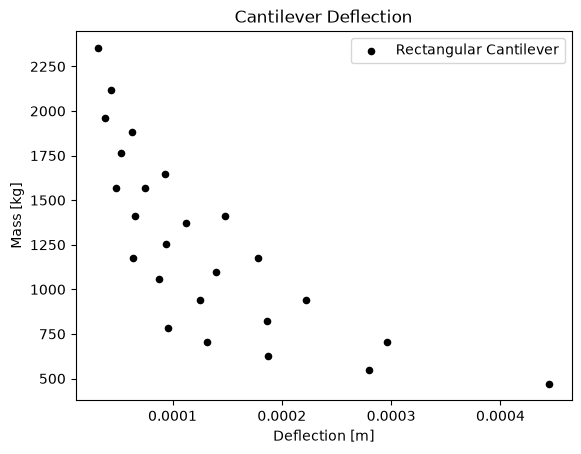

In [78]:
firstPlot = searcher.df.plot(x='deflection',y='mass',kind='scatter',title='Cantilever Deflection',xlabel='Deflection [m]',ylabel='Mass [kg]',color='black',label = 'Rectangular Cantilever')

Everything is set up and running, and we want to build a more detailed assessment. This will just be a way to build an I-beam instead of a rectangular cross-section, but it could also be a way to calculate deflection from a separate FE package

In [79]:
sectionThickness = 0.1
def ibeamCantileverDeflection(depth,width,**kwargs):
	I = (depth**3 * width - (depth-2*sectionThickness)**3 * (width - sectionThickness)) / 12
	deflection = load * length**3 / (4 * youngsModulus * I)
	return {'deflection':deflection}

newDeflectionStage = stage(ibeamCantileverDeflection,inputs = ['depth','width'],name = 'New Cantilever deflection')

def ibeamMass(depth,width,**kwargs):
	volume = depth * width * length - (depth-2*sectionThickness) * (width-sectionThickness) * length
	mass = volume * density
	return {'mass':mass}

newMassStage = stage(ibeamMass,inputs = ['depth','width'],name = 'New Cantilever mass')

runner.stages = [newDeflectionStage,newMassStage]
runner.runRoutines()


Now let's plot again to compare the new results...

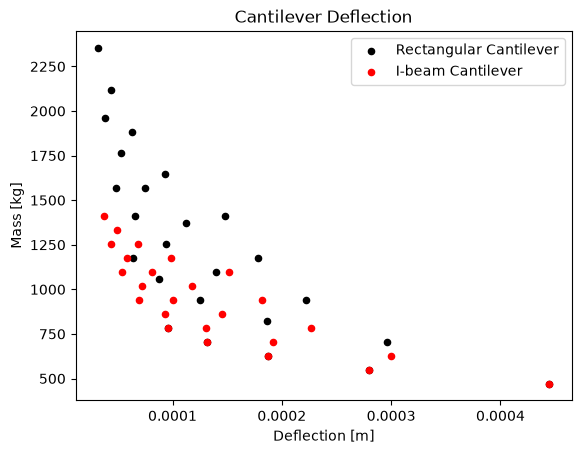

In [80]:
secondPlot = searcher.df.plot(x='deflection',y='mass',kind='scatter',title='Cantilever Deflection',xlabel='Deflection [m]',ylabel='Mass [kg]',color='red',label = 'I-beam Cantilever',ax=firstPlot)
legend = secondPlot.legend()

from IPython.display import display
display(secondPlot.figure)